In [1]:
# src/wrangle.py
import glob
import pandas as pd

def clean_files(filepath):
    ...  # paste your function body from notebook 2.1

In [2]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

In [3]:
from wrangle import clean_files

df = clean_files("../data/raw/buenos-aires-real-estate-*.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6247 entries, 0 to 6246
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price_aprox_usd        6247 non-null   float64
 1   surface_covered_in_m2  6247 non-null   float64
 2   lat                    6247 non-null   float64
 3   lon                    6247 non-null   float64
 4   neighborhood           6247 non-null   str    
dtypes: float64(4), str(1)
memory usage: 244.2 KB


In [4]:
X = df[["surface_covered_in_m2"]]   # double brackets -> 2D DataFrame
y = df["price_aprox_usd"]           # single brackets -> 1D Series

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")
print(X.shape, y.shape)

Training set size: 4997
Test set size: 1250
(6247, 1) (6247,)


In [5]:
from wrangle import merged_files, filter_df, outliers_df, modify_cols, DROP_COLS

pattern = "../data/raw/buenos-aires-real-estate-*.csv"
before_dropna = (
    merged_files(pattern)
    .pipe(filter_df)
    .pipe(outliers_df)
    .pipe(modify_cols)
    .drop(columns=DROP_COLS)
)
print(len(before_dropna))
print(before_dropna.isna().sum())


6507
price_aprox_usd            0
surface_covered_in_m2      0
lat                      260
lon                      260
neighborhood               0
dtype: int64


In [6]:
# Baseline: predict the training mean for every test apartment
y_mean = y_train.mean()
print("Mean house price:", y_mean)

y_pred_baseline = [y_mean] * len(y_test)
mae_baseline = mean_absolute_error(y_test, y_pred_baseline)
print("Baseline MAE:", mae_baseline)

Mean house price: 133867.2574564739
Baseline MAE: 45233.258924130474


In [7]:
# Linear regression: instantiate, then fit on the training set only
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[2275.28]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['surface_covered_in_m2']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.072e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [8]:
y_pred_train = model_lr.predict(X_train)

mae_train = mean_absolute_error(y_train, y_pred_train)
rmse_train = root_mean_squared_error(y_train, y_pred_train)
r2_train = r2_score(y_train, y_pred_train)

print(f"Training MAE: ${mae_train:,.2f}")
print(f"Training RMSE: ${rmse_train:,.2f}")
print(f"Training R²: {r2_train:.4f}")

Training MAE: $30,691.51
Training RMSE: $42,238.10
Training R²: 0.4845


In [9]:
y_pred_test = model_lr.predict(X_test)

mae_test = mean_absolute_error(y_test, y_pred_test)
rmse_test = root_mean_squared_error(y_test, y_pred_test)
r2_test = r2_score(y_test, y_pred_test)

print(f"Test MAE: ${mae_test:,.2f}")
print(f"Test RMSE: ${rmse_test:,.2f}")
print(f"Test R²: {r2_test:.4f}")

Test MAE: $31,842.67
Test RMSE: $45,142.72
Test R²: 0.4529


In [10]:
metrics_comparison = pd.DataFrame({
    'Metric': ['MAE', 'RMSE', 'R²'],
    'Training': [mae_train, rmse_train, r2_train],
    'Test': [mae_test, rmse_test, r2_test]
})
print(metrics_comparison)

print(f"\nRMSE difference (Test - Train): ${rmse_test - rmse_train:,.2f}")
print(f"Baseline MAE: ${mae_baseline:,.2f}")
print(f"Model test MAE: ${mae_test:,.2f}")
print(f"Improvement over baseline: {(1 - mae_test / mae_baseline):.1%}")

  Metric      Training          Test
0    MAE  30691.508395  31842.668641
1   RMSE  42238.099467  45142.723388
2     R²      0.484488      0.452866

RMSE difference (Test - Train): $2,904.62
Baseline MAE: $45,233.26
Model test MAE: $31,842.67
Improvement over baseline: 29.6%


In [11]:
intercept = model_lr.intercept_
coefficient = model_lr.coef_[0]

print(f"Intercept: ${intercept:,.2f}")
print(f"Coefficient: ${coefficient:,.2f} per square meter")

Intercept: $10,721.61
Coefficient: $2,275.28 per square meter


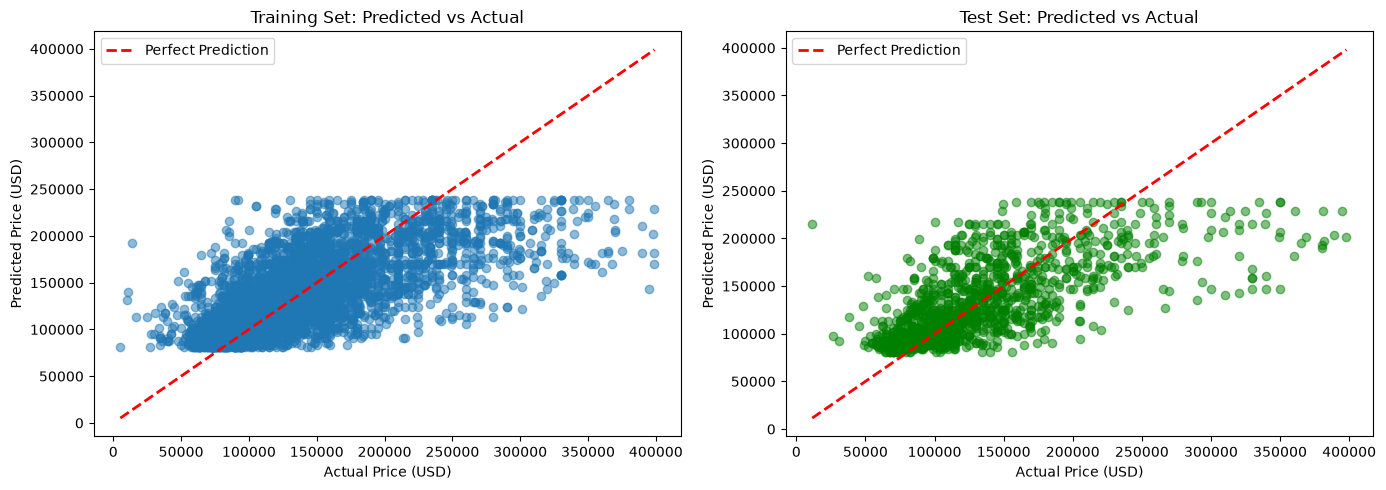

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_train, y_pred_train, alpha=0.5)
axes[0].plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()],
             'r--', lw=2, label='Perfect Prediction')
axes[0].set_xlabel('Actual Price (USD)')
axes[0].set_ylabel('Predicted Price (USD)')
axes[0].set_title('Training Set: Predicted vs Actual')
axes[0].legend()

axes[1].scatter(y_test, y_pred_test, alpha=0.5, color='green')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
             'r--', lw=2, label='Perfect Prediction')
axes[1].set_xlabel('Actual Price (USD)')
axes[1].set_ylabel('Predicted Price (USD)')
axes[1].set_title('Test Set: Predicted vs Actual')
axes[1].legend()

plt.tight_layout()

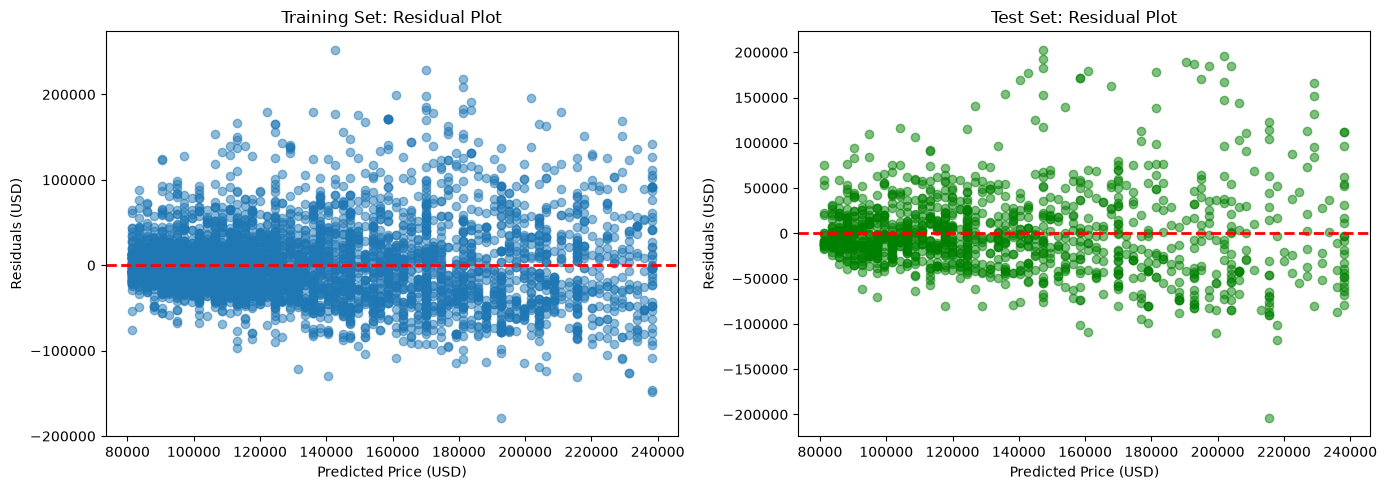

In [13]:
residuals_train = y_train - y_pred_train
residuals_test = y_test - y_pred_test

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_pred_train, residuals_train, alpha=0.5)
axes[0].axhline(y=0, color='r', linestyle='--', lw=2)
axes[0].set_xlabel('Predicted Price (USD)')
axes[0].set_ylabel('Residuals (USD)')
axes[0].set_title('Training Set: Residual Plot')

axes[1].scatter(y_pred_test, residuals_test, alpha=0.5, color='green')
axes[1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[1].set_xlabel('Predicted Price (USD)')
axes[1].set_ylabel('Residuals (USD)')
axes[1].set_title('Test Set: Residual Plot')

plt.tight_layout()

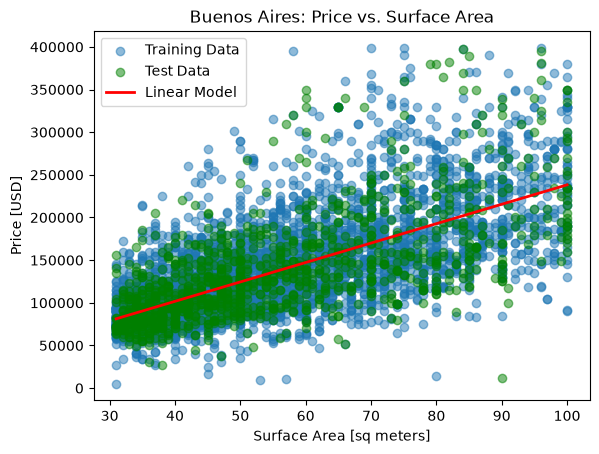

In [14]:
fig, ax = plt.subplots()
ax.scatter(X_train, y_train, alpha=0.5, label='Training Data')
ax.scatter(X_test, y_test, alpha=0.5, color='green', label='Test Data')

x_line = pd.DataFrame({
    "surface_covered_in_m2": np.linspace(
        X_train["surface_covered_in_m2"].min(),
        X_train["surface_covered_in_m2"].max(), 100)
})
ax.plot(x_line["surface_covered_in_m2"], model_lr.predict(x_line),
        color="red", linewidth=2, label="Linear Model")

ax.set_xlabel("Surface Area [sq meters]")
ax.set_ylabel("Price [USD]")
ax.set_title("Buenos Aires: Price vs. Surface Area")
ax.legend()

In [15]:
from pathlib import Path
Path("../reports/figures").mkdir(parents=True, exist_ok=True)
fig.savefig("../reports/figures/price_vs_surface.png", dpi=150, bbox_inches="tight")

## Headline results

A single-feature linear model (covered surface area) cuts test MAE from $45.2k (mean baseline) to $31.8k (-29.6%), with test R² = 0.45. Train and test metrics agree, so the limit is the feature set, not overfitting. Each extra m² is associated with about $2,275 of additional price. Errors grow with price (residuals fan out above about $150k), and predictions cap near $240k. Lessons 2.3 and 2.4 add location and regularization to address this.

![Price vs surface area](reports/figures/price_vs_surface.png)